# Open Coverage - KumoRFM Hackathon Challenge

**About Open-Coverage and this hackathon challenge**
Open coverage is a set of health insurance tools that help US consumers understand and how to optimize their insurance and providers.

**Challenge**: A large part of the challenge of optimizing health insurance policy choices, we need to predict a consumer's healthcare utilization over a given year. Fortunately demographics with utilization data is available from MEPS and for this hackathon challenge  we created a model to predict a US consumer's healthcare utilization over a year given a few demographic details about themselves. We used a dataset we compiled from the US Gov's medical expenditure survey (https://meps.ahrq.gov/mepsweb). Using KumoRFM we've been able to predict fields like number of primary care visits, prescriptions, emergency visits, etc with a decent level of accuracy.

https://docs.google.com/forms/d/e/1FAIpQLSdbpDfsYgtbFFUmqtFY48qz3ZhnYa3TLJjszgIoYRrnHqtrnA/viewform

In [148]:
!pip install kumoai

In [2]:
import kumoai.experimental.rfm as rfm

## Step 2. Get an API key

You will need an API key to make calls to KumoRFM.
Use the widget below to generate one for free by clicking "Generate API Key".
If you don't have a KumoRFM account, the widget will prompt you to signup.

You will see the following when your key has been created successfully:

<div align="left">
  <img src="https://kumo-sdk-public.s3.us-west-2.amazonaws.com/rfm-colabs/api-key-created.png" width="300" />
</div>

In [3]:
import os

if not os.environ.get("KUMO_API_KEY"):
    rfm.authenticate()

## Step 3. Initialize a client

If you completed step 2 via the widget, you don't need to change anything. `KUMO_API_KEY` is already set as environment variable.

If you bring the API key from the website, you can manually change the `KUMO_API_KEY` below:


In [79]:
# Initialize a Kumo client with your API key:
KUMO_API_KEY = os.environ.get("KUMO_API_KEY")
rfm.init(api_key=KUMO_API_KEY)

Client has already been created. To re-initialize Kumo, please start a new interpreter. No changes will be made to the current session.



# Import the cleaned and joined MEPS Data

In [137]:
import pandas as pd

df = pd.read_csv('/content/MEPS_demographics_and_counts_joined.csv')
df.head()

,person_id,age_years_2022,gender,race_ethnicity,hispanic_origin_category,census_region,education_years,highest_degree_achieved,family_income_2022,poverty_level_pct,...,hopelessness_frequency_30d,sadness_frequency_30d,pcp_visits,outpatient_visits,er_visits,inpatient_admits,home_health_visits,rx_fills,dental_visits,equipment_purchases
0,2460002101,77,2,3,9,2,6,1,22000,156.74,...,2,2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2460006101,64,-1,2,9,2,14,7,5000,32.84,...,-1,-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2460006102,67,-1,2,9,2,17,5,30740,219.01,...,-1,-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2460010101,29,-1,5,9,4,16,4,106483,699.40,...,-1,-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2460018101,51,2,2,9,1,16,4,45000,295.57,...,1,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [138]:
new_row = {
    'person_id': 1111,
    'age_years_2022': 100,
    'gender': 1.0
}

# Use ignore_index=True to reindex the DataFrame after appending
df = pd.concat([df, pd.DataFrame([new_row])], ignore_index=True)
display(df.tail())

# df['person_id_primary'] = df['person_id']

,person_id,age_years_2022,gender,race_ethnicity,hispanic_origin_category,census_region,education_years,highest_degree_achieved,family_income_2022,poverty_level_pct,...,hopelessness_frequency_30d,sadness_frequency_30d,pcp_visits,outpatient_visits,er_visits,inpatient_admits,home_health_visits,rx_fills,dental_visits,equipment_purchases
22427,2799694102,85,1.0,2.0,9.0,2.0,10.0,2.0,58720.0,331.96,...,0.0,0.0,14.0,7.0,2.0,0.0,4.0,16.0,0.0,2.0
22428,2799695101,62,2.0,2.0,9.0,3.0,13.0,3.0,15008.0,98.57,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
22429,2799698101,65,-1.0,2.0,9.0,4.0,13.0,7.0,37819.0,269.44,...,-1.0,-1.0,16.0,0.0,0.0,0.0,0.0,25.0,2.0,4.0
22430,2799700101,85,2.0,3.0,9.0,2.0,9.0,2.0,10884.0,77.54,...,4.0,4.0,6.0,1.0,0.0,0.0,12.0,25.0,0.0,0.0
22431,1111,100,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


| **Category**               | **Feature**                 | **Variable Name**                  | **Description**                                                    |
| -------------------------- | --------------------------- | ---------------------------------- | ------------------------------------------------------------------ |
| **Identifiers**            | Person ID                   | `person_id`                        | Unique person identifier (for merges)                              |
| **Demographics**           | Age                         | `age_years_2022`                   | Age as of 12/31/2022 (imputed)                                     |
|                            | Sex                         | `gender`                           | Survey-reported gender (1 = Male, 2 = Female)                      |
|                            | Race/Ethnicity              | `race_ethnicity`                   | Detailed race and ethnicity categories                             |
|                            | Hispanic Category           | `hispanic_origin_category`         | Categorical breakdown of Hispanic origin                           |
|                            | Region                      | `census_region`                    | Census region (Northeast, Midwest, South, West)                    |
|                            | Metro Status                | `metro_status`                     | 1 = MSA • 2 = non-MSA • 3 = unknown                                |
| **Socioeconomic**          | Education (years)           | `education_years`                  | Years of schooling when first entered MEPS                         |
|                            | Highest Degree              | `highest_degree_achieved`          | Highest educational degree achieved                                |
|                            | Family Income               | `family_income_2022`               | Total family income in 2022                                        |
|                            | Poverty Level (%)           | `poverty_level_pct`                | Family income as % of federal poverty line                         |
|                            | Poverty Category            | `poverty_category`                 | Poverty status category (<100%, 100–199%, ≥200%)                   |
|                            | Employment Status           | `employment_status`                | Employed full-/part-time vs. unemployed/inactive                   |
|                            | Hours Worked/Week           | `hours_worked_per_week`            | Usual hours worked/week                                            |
|                            | Industry Category           | `occupation_industry_category`     | Broad industry category of current/most recent job                 |
|                            | Family Size                 | `family_size`                      | Number of people in the family unit                                |
|                            | Marital Status              | `marital_status`                   | Married vs. single/divorced/widowed                                |
|                            | Spouse Present              | `spouse_in_household`              | Indicates if spouse resides in same household                      |
| **Access & Utilization**   | Insurance Status            | `insurance_coverage_type`          | 1 = Any private • 2 = Public only • 3 = Uninsured                  |
|                            | Usual Source of Care        | `has_usual_source_of_care`         | Has a usual source of medical care                                 |
|                            | Location of Usual Care      | `usual_care_location_type`         | Type/location of usual source (clinic, doctor’s office, etc.)      |
|                            | Could Not Afford Care       | `delayed_care_due_to_cost`         | Delayed/forgone medical care due to cost                           |
|                            | Delayed Medicine (Cost)     | `delayed_prescription_due_to_cost` | Delayed getting prescription medicine because of cost              |
|                            | Food Stamp Receipt          | `received_snap`                    | Received SNAP benefits                                             |
|                            | Food Stamp Value            | `snap_benefit_value_2022`          | Total value of SNAP benefits received in 2022                      |
| **Behaviors & Lifestyle**  | BMI                         | `bmi`                              | Body Mass Index (>17) from Round 4/5                               |
|                            | Smoking Frequency           | `smoking_frequency`                | “How often use tobacco” in past 12 months                          |
|                            | Alcohol Consumption         | `alcohol_consumption_frequency`    | Alcohol drinking in past 12 months                                 |
|                            | Exercise                    | `exercise_days_per_week`           | Average days/week of moderate/vigorous activity                    |
|                            | English Proficiency         | `english_proficiency`              | Self-rated English speaking ability                                |
|                            | Nativity                    | `us_born_flag`                     | Born in the United States?                                         |
|                            | Years in U.S.               | `years_in_us`                      | Years lived in the United States                                   |
| **Functional & Cognitive** | Difficulty Lifting          | `difficulty_lifting_carrying`      | Serious difficulty lifting or carrying                             |
|                            | Difficulty Walking/Stairs   | `difficulty_walking_stairs`        | Serious difficulty walking or climbing stairs                      |
|                            | Any Activity Limitation     | `any_activity_limitation`          | Any limitation in usual activities due to health                   |
|                            | Cognitive Limitation        | `cognitive_limitation`             | Serious difficulty concentrating, remembering, or making decisions |
|                            | Psychological Distress (K6) | `k6_distress_score`                | Kessler 6-item psychological distress score (0–24)                 |
|                            | Feelings of Hopelessness    | `hopelessness_frequency_30d`       | Frequency of feeling hopeless in past 30 days                      |
|                            | Feelings of Sadness         | `sadness_frequency_30d`            | Frequency of feeling sad or depressed in past 30 days              |
| **Health Status**          | Chronic Condition Count     | `chronic_condition_count`          | Number of chronic conditions                                       |
| **Outcome**                | Total Expenditures (target) | `total_expenditures_2022`          | Sum of all payments in 2022                                        |


We can inspect the data and its types in-memory:

In [139]:
# Inspect the data types of a `pandas.DataFrame`:
df.dtypes

,0
person_id,int64
age_years_2022,int64
gender,float64
race_ethnicity,float64
hispanic_origin_category,float64
census_region,float64
education_years,float64
highest_degree_achieved,float64
family_income_2022,float64
poverty_level_pct,float64


## Step 5. Create KumoRFM tables

In [141]:
utilizations = rfm.LocalTable(df, name="utilizations").infer_metadata()


If you prefer more explicit control, you can manually assign metadata during table creation instead of relying on automatic inference:

In [140]:
utilizations = rfm.LocalTable(
    df,
    name="utilizations",
    primary_key="person_id",
)

In [142]:
utilizations['pcp_visits'].stype = 'categorical'
utilizations['outpatient_visits'].stype = 'categorical'
utilizations['gender'].style = 'categorical'
utilizations['rx_fills'].style = 'categorical'
utilizations['dental_visits'].style = 'categorical'
utilizations['equipment_purchases'].style = 'categorical'

You can inspect the metadata of the table ...

In [123]:
utilizations.print_metadata()

### 🏷️ Metadata of Table `utilizations` (22,432 rows)

name,dtype,stype,is_primary_key,is_time_column
person_id,int,ID,False,False
age_years_2022,int,numerical,False,False
gender,float,categorical,False,False
race_ethnicity,float,categorical,False,False
hispanic_origin_category,float,categorical,False,False
census_region,float,categorical,False,False
education_years,float,categorical,False,False
highest_degree_achieved,float,categorical,False,False
family_income_2022,float,numerical,False,False
poverty_level_pct,float,numerical,False,False


## Step 6. Create a graph in two simple steps

 **1. Select the tables:**

In [132]:
graph = rfm.LocalGraph(tables=[
    utilizations
])

**2. Link the tables:**

You can verify that graph connectivity is set up by visualizing the graph ...

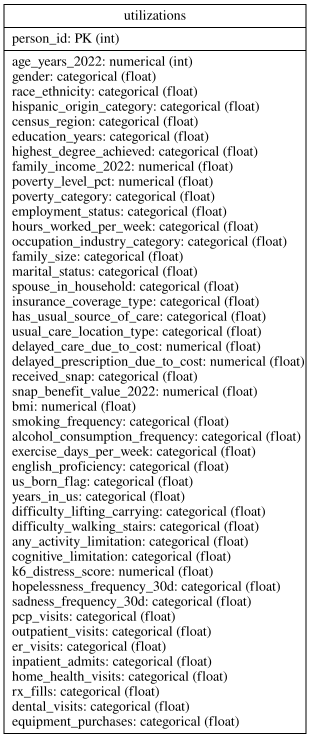

In [143]:
# Requires graphviz to be installed
# counts.primary_key = None
graph.visualize();

... or by printing all necessary information:

In [144]:
graph.print_metadata()
graph.print_links()

### 🗂️ Graph Metadata

name,primary_key,time_column
utilizations,person_id,-


### 🕸️ Graph Links (FK ↔️ PK)

## Step 7. Write a predictive query

You are now ready to plug your graph into `KumoRFM` to make predictions!

The great thing about the graph is that it's a one-time setup—once it's in place, you can generate a variety of predictions from it and power many business use cases.

In [145]:
model = rfm.KumoRFM(graph)

Output()

#### pQueries: How you talk to your model

Learn more about writing all kinds of pQueries [here](https://kumo.ai/docs/pquery-structure/).

In [147]:
query = "PREDICT utilizations.pcp_visits FOR utilizations.person_id=1111"
df = model.predict(query)
display(df)

Output()

,ENTITY,CLASS,SCORE,PREDICTED
0,1111,0.0,0.133021,True
1,1111,1.0,0.101039,False
2,1111,2.0,0.098914,False
3,1111,6.0,0.097533,False
4,1111,3.0,0.097406,False
5,1111,8.0,0.096621,False
6,1111,5.0,0.094853,False
7,1111,4.0,0.094385,False
8,1111,9.0,0.093388,False
9,1111,7.0,0.092841,False
